## Instructor Effectiveness Modeling

## Problem Statement

The objective of this project is to analyze instructor effectiveness in an EdTech platform using learner outcomes, engagement metrics, and feedback data.

The dataset contains multiple course batches taught by different instructors. The project involves exploratory data analysis, defining an Instructor Effectiveness Score, aggregating batch-level information to the instructor level, building a machine learning model, evaluating its performance, and interpreting the results.

The instructors will be categorized into three effectiveness tiers: Low, Medium, and High.

Important assumption: The effectiveness score developed in this project is a data-based proxy for instructor effectiveness, not a direct measurement of teaching quality.

In [1]:
import pandas as pd

df = pd.read_csv(
    "instructor_effectiveness_dataset_2000_rows - instructor_effectiveness_dataset_2000_rows.csv.csv"
)
print("Dataset Shape:", df.shape)

display(df.head())

Dataset Shape: (2000, 12)


,batch_id,instructor_id,course_id,completion_rate,avg_score_improvement,avg_quiz_score,dropout_rate,avg_watch_time,assignment_submission_rate,forum_activity_rate,avg_feedback_score,feedback_response_rate
0,B_1861,I_044,C_01,0.300000,14.225955,73.546528,0.647423,0.774572,0.790918,0.108414,3.766211,0.533193
1,B_0354,I_119,C_06,0.657220,22.871110,77.312331,0.425098,0.494936,0.998566,0.280550,5.000000,0.734087
2,B_1334,I_050,C_03,0.300000,16.087517,79.563687,0.700000,0.977901,0.807298,0.207013,3.517386,0.681433
3,B_0906,I_024,C_21,0.639507,24.260687,99.295316,0.334657,0.846515,0.544555,0.306395,4.207578,1.000000
4,B_1290,I_001,C_08,0.527302,31.081556,99.393425,0.521099,0.917450,0.865885,0.252289,4.426230,0.696710


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    balanced_accuracy_score,
    f1_score
)

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

RANDOM_STATE = 42

In [3]:
print("Column names:")
for column in df.columns:
    print(column)

Column names:
batch_id
instructor_id
course_id
completion_rate
avg_score_improvement
avg_quiz_score
dropout_rate
avg_watch_time
assignment_submission_rate
forum_activity_rate
avg_feedback_score
feedback_response_rate


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   batch_id                    2000 non-null   object 
 1   instructor_id               2000 non-null   object 
 2   course_id                   2000 non-null   object 
 3   completion_rate             2000 non-null   float64
 4   avg_score_improvement       2000 non-null   float64
 5   avg_quiz_score              2000 non-null   float64
 6   dropout_rate                2000 non-null   float64
 7   avg_watch_time              2000 non-null   float64
 8   assignment_submission_rate  2000 non-null   float64
 9   forum_activity_rate         2000 non-null   float64
 10  avg_feedback_score          2000 non-null   float64
 11  feedback_response_rate      2000 non-null   float64
dtypes: float64(9), object(3)
memory usage: 187.6+ KB


In [5]:
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
batch_id,2000,2000,B_1861,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
instructor_id,2000,120,I_062,31,NaN,NaN,NaN,NaN,NaN,NaN,NaN
course_id,2000,25,C_21,91,NaN,NaN,NaN,NaN,NaN,NaN,NaN
completion_rate,2000.0,NaN,NaN,NaN,0.602808,0.159667,0.3,0.48926,0.603091,0.712797,0.98
avg_score_improvement,2000.0,NaN,NaN,NaN,27.035844,5.716641,6.15924,23.124673,26.938629,30.8856,40.0
avg_quiz_score,2000.0,NaN,NaN,NaN,77.956126,10.695618,40.386725,70.89759,78.020567,85.444286,100.0
dropout_rate,2000.0,NaN,NaN,NaN,0.394883,0.162747,0.02,0.280035,0.39482,0.511432,0.7
avg_watch_time,2000.0,NaN,NaN,NaN,0.776515,0.145231,0.28744,0.675076,0.78033,0.894242,1.0
assignment_submission_rate,2000.0,NaN,NaN,NaN,0.753188,0.148058,0.251111,0.65211,0.75638,0.856458,1.0
forum_activity_rate,2000.0,NaN,NaN,NaN,0.2503,0.10064,0.0,0.179845,0.249771,0.319204,0.641111


In [6]:
print("Missing values by column:")
display(df.isnull().sum().to_frame("Missing Values"))

print("Total missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Missing values by column:


,Missing Values
batch_id,0
instructor_id,0
course_id,0
completion_rate,0
avg_score_improvement,0
avg_quiz_score,0
dropout_rate,0
avg_watch_time,0
assignment_submission_rate,0
forum_activity_rate,0


Total missing values: 0
Duplicate rows: 0


In [7]:
print("Unique batch IDs:", df["batch_id"].nunique())
print("Unique instructor IDs:", df["instructor_id"].nunique())
print("Unique course IDs:", df["course_id"].nunique())

print("\nBatch ID duplicates:", df["batch_id"].duplicated().sum())

Unique batch IDs: 2000
Unique instructor IDs: 120
Unique course IDs: 25

Batch ID duplicates: 0


In [8]:
required_columns = [
    "batch_id",
    "instructor_id",
    "course_id",
    "completion_rate",
    "dropout_rate",
    "avg_score_improvement",
    "avg_quiz_score",
    "avg_watch_time",
    "assignment_submission_rate",
    "forum_activity_rate",
    "avg_feedback_score",
    "feedback_response_rate"
]

missing_columns = [
    col for col in required_columns if col not in df.columns
]

if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

print("All required columns are present.")

All required columns are present.


In [9]:
rate_columns = [
    "completion_rate",
    "dropout_rate",
    "avg_watch_time",
    "assignment_submission_rate",
    "forum_activity_rate",
    "feedback_response_rate"
]

for col in rate_columns:
    invalid_count = ((df[col] < 0) | (df[col] > 1)).sum()
    print(f"{col}: {invalid_count} values outside 0-1")

feedback_invalid = (
    (df["avg_feedback_score"] < 1) |
    (df["avg_feedback_score"] > 5)
).sum()

print("Feedback scores outside 1-5:", feedback_invalid)
print(
    "Negative score improvements:",
    (df["avg_score_improvement"] < 0).sum()
)

completion_rate: 0 values outside 0-1
dropout_rate: 0 values outside 0-1
avg_watch_time: 0 values outside 0-1
assignment_submission_rate: 0 values outside 0-1
forum_activity_rate: 0 values outside 0-1
feedback_response_rate: 0 values outside 0-1
Feedback scores outside 1-5: 0
Negative score improvements: 0


In [10]:
numeric_columns = df.select_dtypes(include=np.number).columns.tolist()

print("Numerical columns:")
print(numeric_columns)

print("\nNon-numeric columns:")
print(df.select_dtypes(exclude=np.number).columns.tolist())

Numerical columns:
['completion_rate', 'avg_score_improvement', 'avg_quiz_score', 'dropout_rate', 'avg_watch_time', 'assignment_submission_rate', 'forum_activity_rate', 'avg_feedback_score', 'feedback_response_rate']

Non-numeric columns:
['batch_id', 'instructor_id', 'course_id']


In [11]:
df = df.copy()

# Remove rows missing essential identifiers.
identifier_columns = [
    "batch_id",
    "instructor_id",
    "course_id"
]

before_rows = len(df)

df = df.dropna(subset=identifier_columns).copy()

print("Rows removed due to missing identifiers:", before_rows - len(df))

# Fill missing numerical values with the median.
numeric_columns = df.select_dtypes(include=np.number).columns

for col in numeric_columns:
    if df[col].isnull().any():
        df[col] = df[col].fillna(df[col].median())

# Fill missing categorical values with the most frequent value.
categorical_columns = df.select_dtypes(
    exclude=np.number
).columns

for col in categorical_columns:
    if df[col].isnull().any():
        mode_values = df[col].mode()
        if not mode_values.empty:
            df[col] = df[col].fillna(mode_values.iloc[0])

print("Remaining missing values:", df.isnull().sum().sum())

Rows removed due to missing identifiers: 0
Remaining missing values: 0


In [12]:
duplicate_batch_count = df["batch_id"].duplicated().sum()

print("Duplicate batch IDs before cleaning:", duplicate_batch_count)

if duplicate_batch_count > 0:
    df = df.drop_duplicates(subset=["batch_id"]).copy()

print("Dataset shape after duplicate batch check:", df.shape)

Duplicate batch IDs before cleaning: 0
Dataset shape after duplicate batch check: (2000, 12)


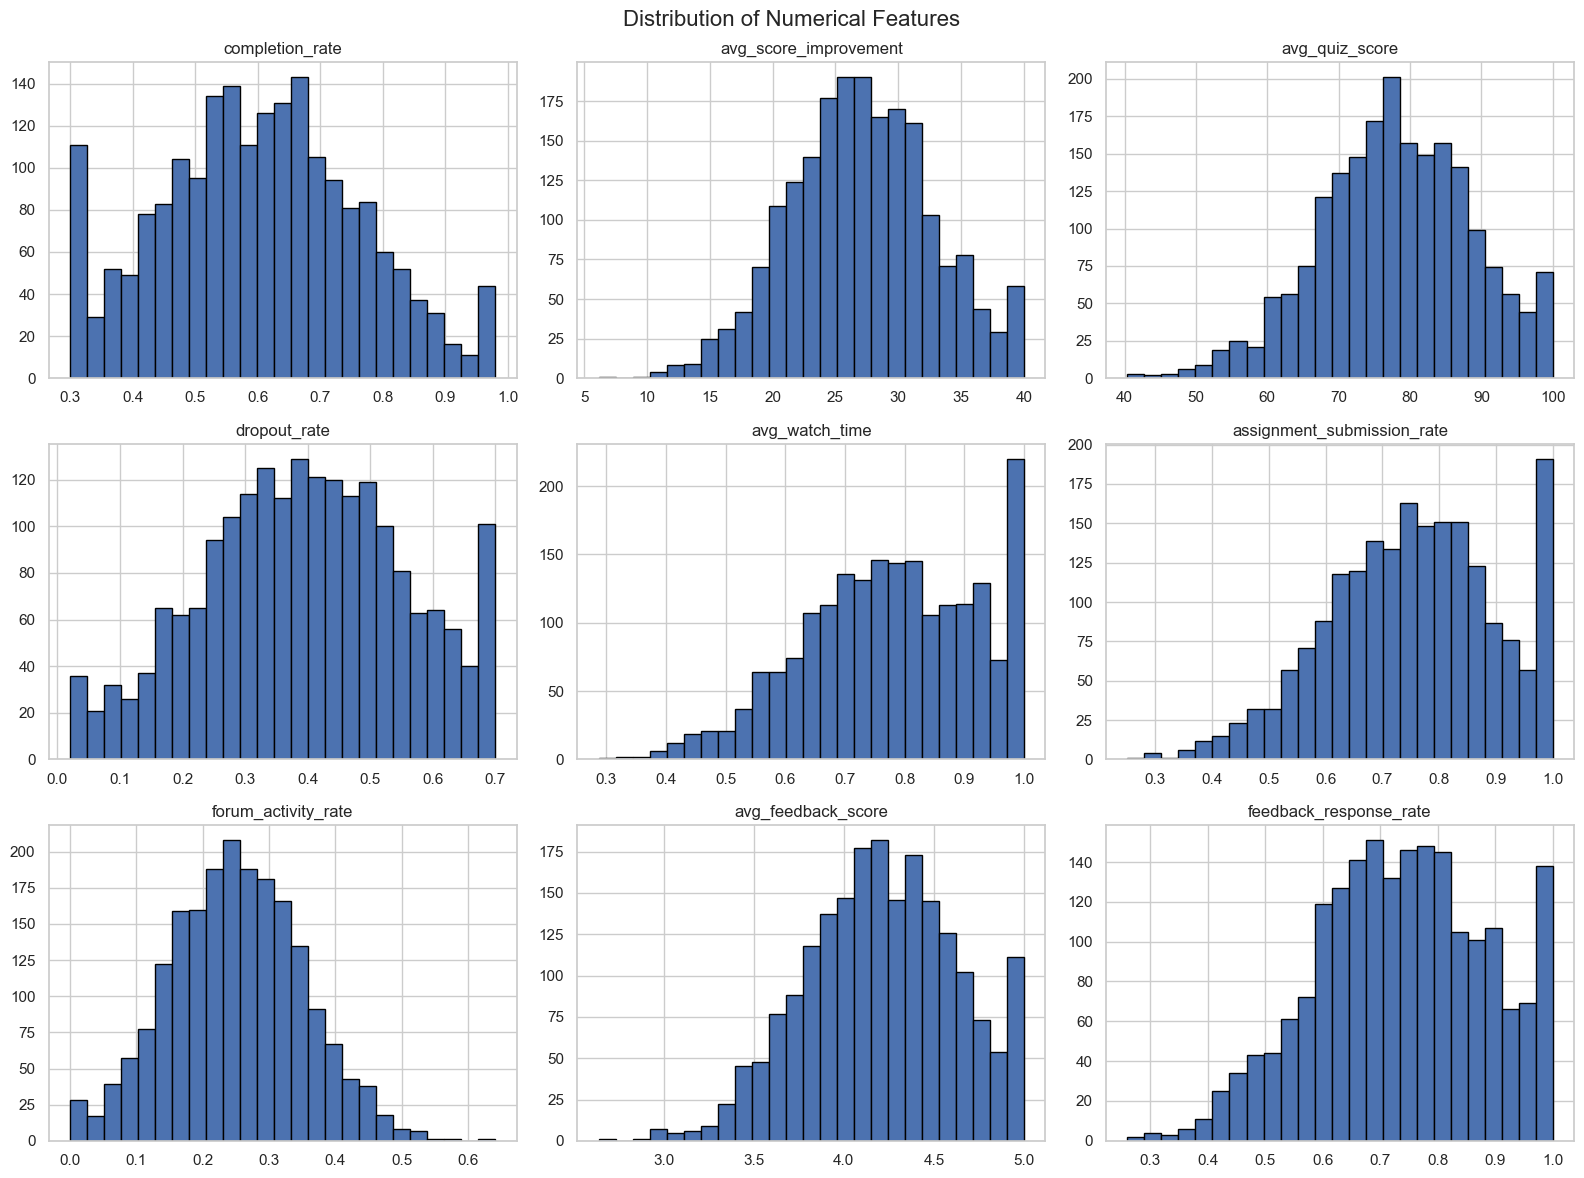

In [13]:
numeric_columns = df.select_dtypes(include=np.number).columns.tolist()

df[numeric_columns].hist(
    figsize=(16, 12),
    bins=25,
    edgecolor="black"
)

plt.suptitle("Distribution of Numerical Features", fontsize=16)
plt.tight_layout()
plt.show()

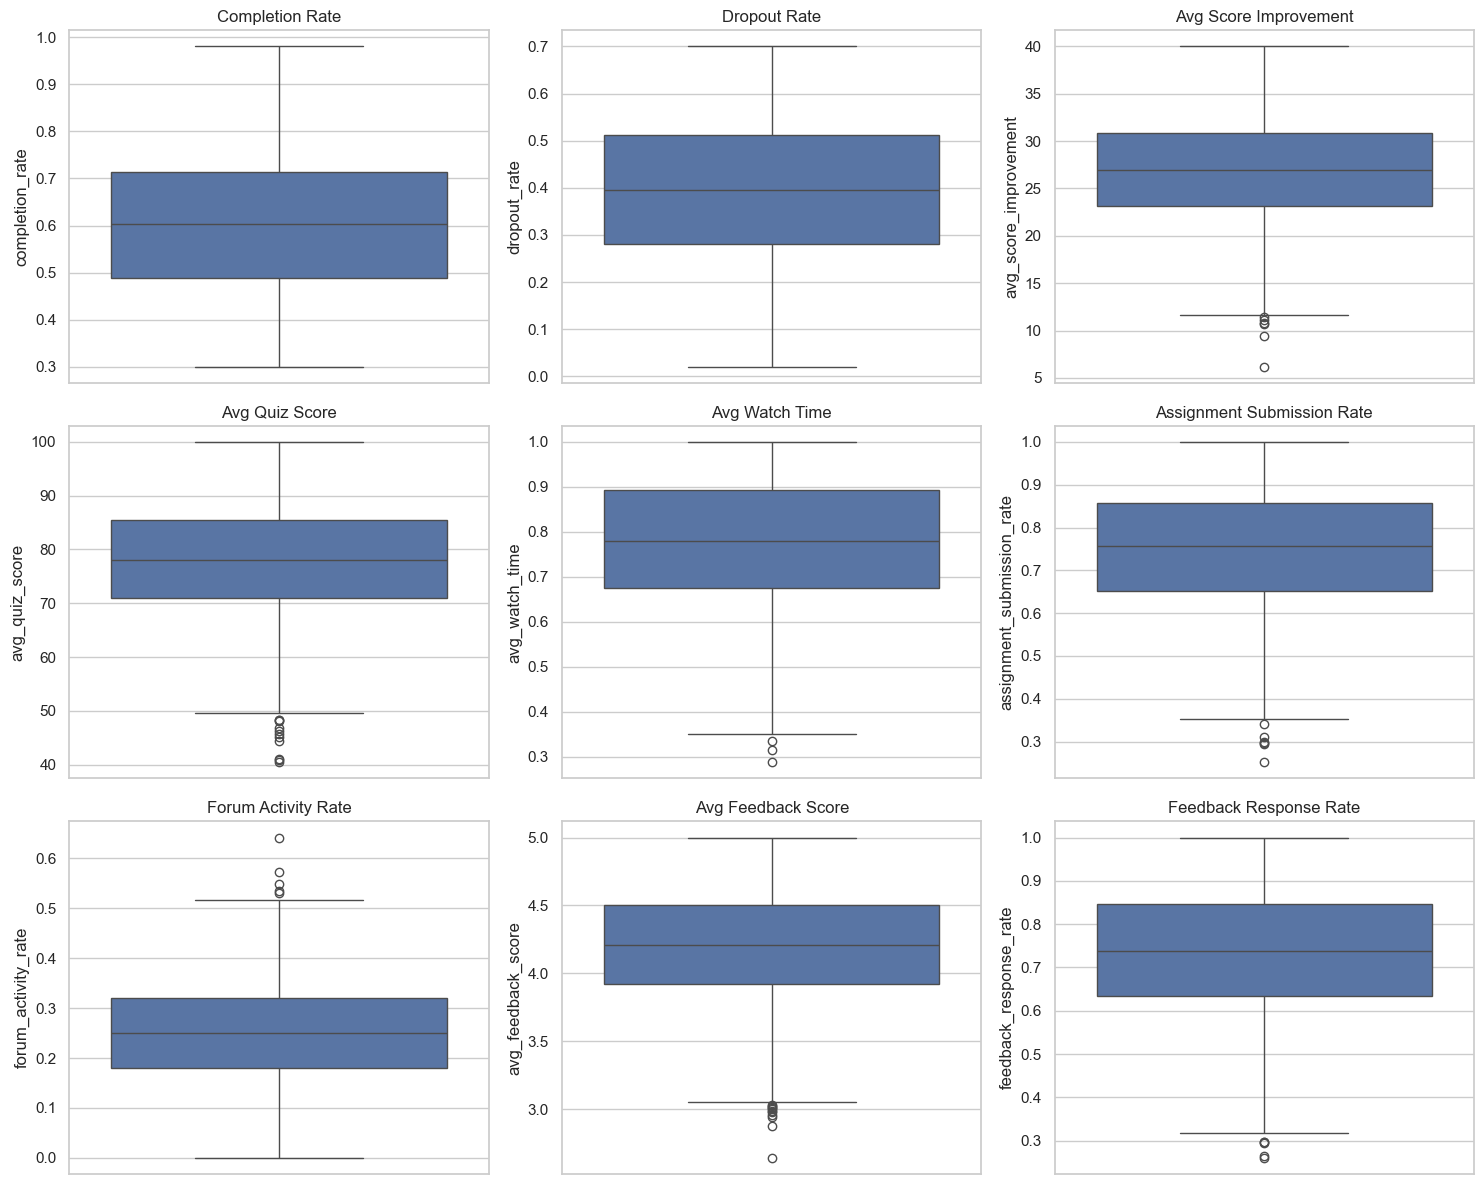

In [14]:
eda_columns = [
    "completion_rate",
    "dropout_rate",
    "avg_score_improvement",
    "avg_quiz_score",
    "avg_watch_time",
    "assignment_submission_rate",
    "forum_activity_rate",
    "avg_feedback_score",
    "feedback_response_rate"
]

fig, axes = plt.subplots(3, 3, figsize=(15, 12))

for col, ax in zip(eda_columns, axes.flatten()):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col.replace("_", " ").title())

plt.tight_layout()
plt.show()

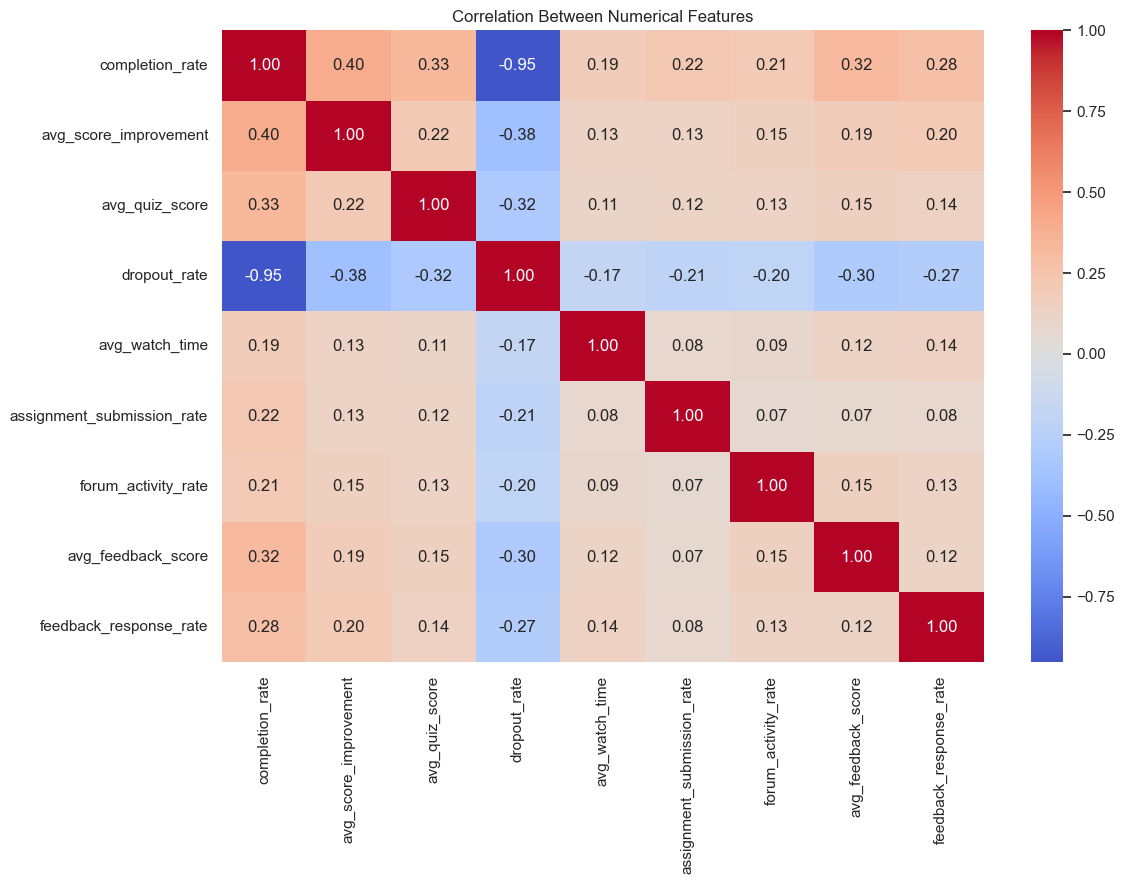

In [15]:
correlation_matrix = df[numeric_columns].corr()

plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0
)

plt.title("Correlation Between Numerical Features")
plt.tight_layout()
plt.show()

In [16]:
corr_pairs = (
    correlation_matrix
    .where(
        np.triu(
            np.ones(correlation_matrix.shape),
            k=1
        ).astype(bool)
    )
    .stack()
    .sort_values(ascending=False)
)

print("Top positive correlations:")
display(corr_pairs.head(10).to_frame("Correlation"))

Top positive correlations:


Correlation
completion_rate       avg_score_improvement          0.404161
                      avg_quiz_score                 0.333307
                      avg_feedback_score             0.315394
                      feedback_response_rate         0.279549
                      assignment_submission_rate     0.221877
avg_score_improvement avg_quiz_score                 0.218788
completion_rate       forum_activity_rate            0.205793
avg_score_improvement feedback_response_rate         0.198923
                      avg_feedback_score             0.190054
completion_rate       avg_watch_time                 0.187633

In [17]:
print("Top negative correlations:")
display(corr_pairs.sort_values().head(10).to_frame("Correlation"))

Top negative correlations:


Correlation
completion_rate            dropout_rate                  -0.953493
avg_score_improvement      dropout_rate                  -0.381354
avg_quiz_score             dropout_rate                  -0.315220
dropout_rate               avg_feedback_score            -0.300556
                           feedback_response_rate        -0.274475
                           assignment_submission_rate    -0.210486
                           forum_activity_rate           -0.200598
                           avg_watch_time                -0.170536
assignment_submission_rate forum_activity_rate            0.066776
                           avg_feedback_score             0.070639

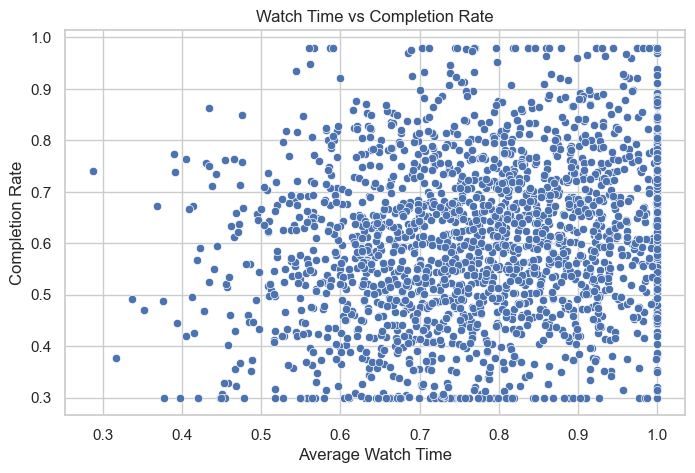

In [18]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="avg_watch_time",
    y="completion_rate"
)

plt.title("Watch Time vs Completion Rate")
plt.xlabel("Average Watch Time")
plt.ylabel("Completion Rate")
plt.show()

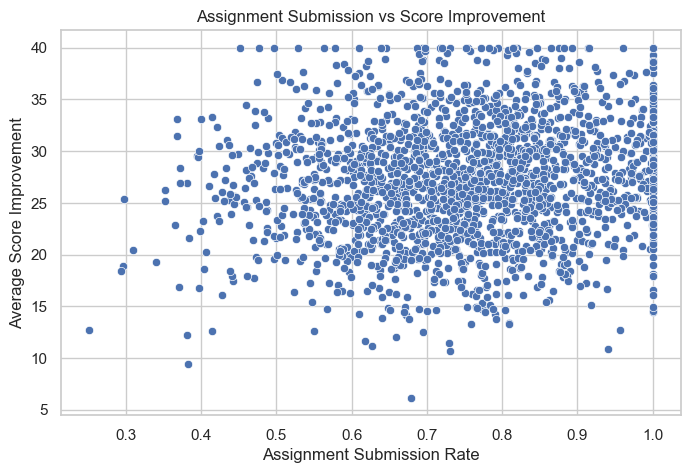

In [19]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="assignment_submission_rate",
    y="avg_score_improvement"
)

plt.title("Assignment Submission vs Score Improvement")
plt.xlabel("Assignment Submission Rate")
plt.ylabel("Average Score Improvement")
plt.show()

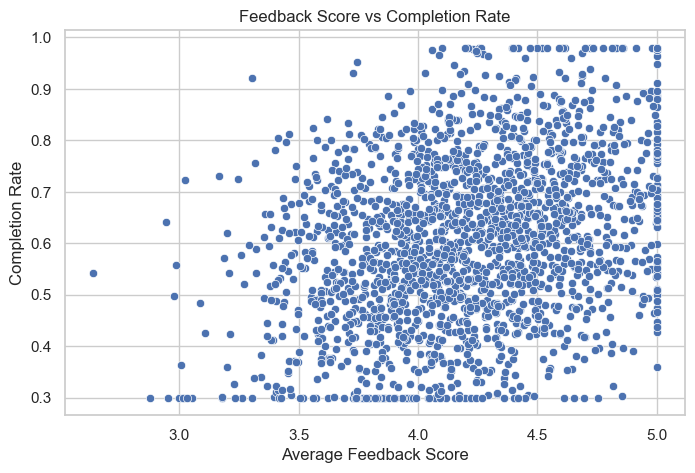

In [20]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="avg_feedback_score",
    y="completion_rate"
)

plt.title("Feedback Score vs Completion Rate")
plt.xlabel("Average Feedback Score")
plt.ylabel("Completion Rate")
plt.show()

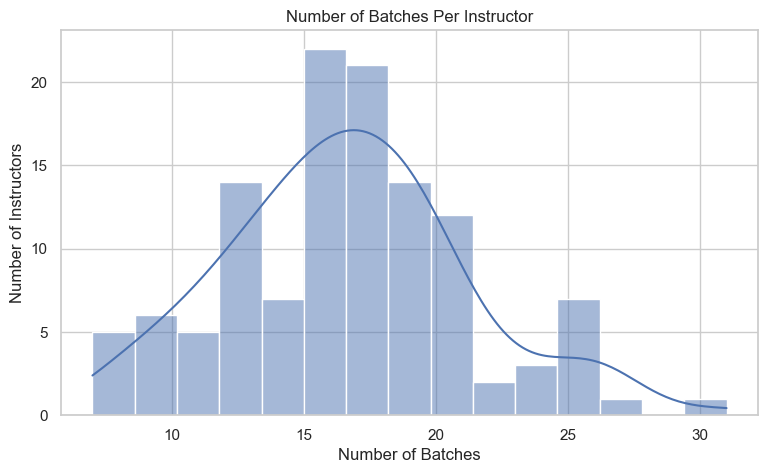

Minimum batches: 7
Maximum batches: 31
Mean batches: 16.67


In [21]:
batches_per_instructor = df.groupby("instructor_id").size()

plt.figure(figsize=(9, 5))

sns.histplot(
    batches_per_instructor,
    bins=15,
    kde=True
)

plt.title("Number of Batches Per Instructor")
plt.xlabel("Number of Batches")
plt.ylabel("Number of Instructors")
plt.show()

print("Minimum batches:", batches_per_instructor.min())
print("Maximum batches:", batches_per_instructor.max())
print("Mean batches:", round(batches_per_instructor.mean(), 2))

In [22]:
print("===== EDA SUMMARY =====")

print("Dataset shape:", df.shape)
print("Unique instructors:", df["instructor_id"].nunique())
print("Unique courses:", df["course_id"].nunique())
print("Missing values:", df.isnull().sum().sum())

print("\nAverage metrics:")
display(df[eda_columns].mean().to_frame("Mean").round(3))

print("\nHighest positive correlations:")
display(corr_pairs.head(5).to_frame("Correlation"))

print("\nLowest correlations:")
display(corr_pairs.sort_values().head(5).to_frame("Correlation"))

===== EDA SUMMARY =====
Dataset shape: (2000, 12)
Unique instructors: 120
Unique courses: 25
Missing values: 0

Average metrics:


,Mean
completion_rate,0.603
dropout_rate,0.395
avg_score_improvement,27.036
avg_quiz_score,77.956
avg_watch_time,0.777
assignment_submission_rate,0.753
forum_activity_rate,0.250
avg_feedback_score,4.207
feedback_response_rate,0.737



Highest positive correlations:


Correlation
completion_rate avg_score_improvement          0.404161
                avg_quiz_score                 0.333307
                avg_feedback_score             0.315394
                feedback_response_rate         0.279549
                assignment_submission_rate     0.221877


Lowest correlations:


Correlation
completion_rate       dropout_rate              -0.953493
avg_score_improvement dropout_rate              -0.381354
avg_quiz_score        dropout_rate              -0.315220
dropout_rate          avg_feedback_score        -0.300556
                      feedback_response_rate    -0.274475

In [23]:
batch_df = df.copy()

# Normalize score improvement and quiz score to 0-1.
score_scaler = MinMaxScaler()

batch_df[
    ["score_improvement_norm", "quiz_score_norm"]
] = score_scaler.fit_transform(
    batch_df[
        ["avg_score_improvement", "avg_quiz_score"]
    ]
)

# Convert feedback rating from 1-5 to 0-1.
batch_df["feedback_norm"] = (
    batch_df["avg_feedback_score"] - 1
) / 4

# Average the three engagement metrics.
engagement_columns = [
    "avg_watch_time",
    "assignment_submission_rate",
    "forum_activity_rate"
]

batch_df["engagement_score"] = (
    batch_df[engagement_columns].mean(axis=1)
)

display(
    batch_df[
        [
            "score_improvement_norm",
            "quiz_score_norm",
            "feedback_norm",
            "engagement_score"
        ]
    ].head()
)

,score_improvement_norm,quiz_score_norm,feedback_norm,engagement_score
0,0.238373,0.556249,0.691553,0.557968
1,0.493839,0.619419,1.000000,0.591351
2,0.293382,0.657185,0.629347,0.664071
3,0.534901,0.988179,0.801895,0.565822
4,0.736459,0.989825,0.856558,0.678542


In [24]:
batch_df["effectiveness_score"] = (
    0.25 * batch_df["completion_rate"]
    + 0.25 * batch_df["score_improvement_norm"]
    + 0.20 * batch_df["quiz_score_norm"]
    + 0.15 * (1 - batch_df["dropout_rate"])
    + 0.10 * batch_df["engagement_score"]
    + 0.05 * batch_df["feedback_norm"]
)

print("Batch-level effectiveness scores created.")

display(
    batch_df[
        [
            "batch_id",
            "instructor_id",
            "effectiveness_score"
        ]
    ].head(10)
)

Batch-level effectiveness scores created.


,batch_id,instructor_id,effectiveness_score
0,B_1861,I_044,0.389104
1,B_0354,I_119,0.607019
2,B_1334,I_050,0.422657
3,B_0906,I_024,0.687716
4,B_1290,I_001,0.696422
5,B_1274,I_026,0.595717
6,B_0939,I_082,0.628138
7,B_1732,I_009,0.604819
8,B_0066,I_114,0.735094
9,B_1324,I_038,0.382896


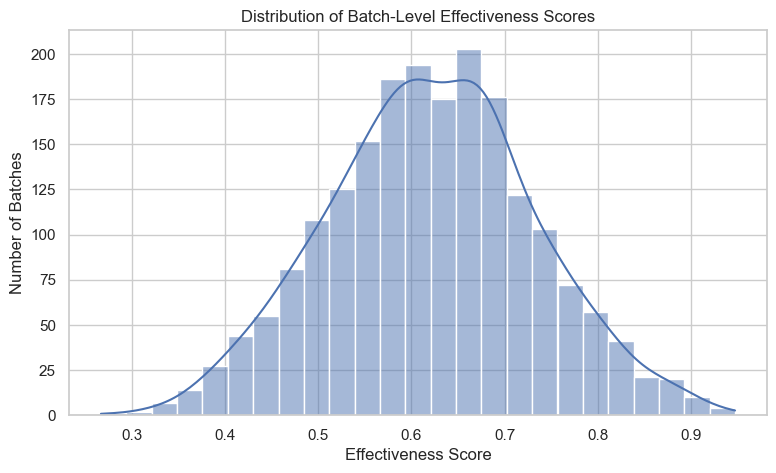

In [25]:
plt.figure(figsize=(9, 5))

sns.histplot(
    batch_df["effectiveness_score"],
    bins=25,
    kde=True
)

plt.title("Distribution of Batch-Level Effectiveness Scores")
plt.xlabel("Effectiveness Score")
plt.ylabel("Number of Batches")
plt.show()

## Effectiveness Score: Assumptions and Justification

The Instructor Effectiveness Score combines learner outcomes, engagement, and feedback into a single numerical measure.

- Completion rate receives a weight of 25% because it represents course completion.
- Score improvement receives a weight of 25% because it represents change in learner assessment performance.
- Average quiz score receives a weight of 20% as an additional learning outcome measure.
- The inverse dropout rate receives a weight of 15% because lower dropout is generally desirable.
- Engagement receives a weight of 10%, divided equally across watch time, assignment submission, and forum activity.
- Feedback receives a weight of 5% after normalization.

The score improvement and quiz score metrics are normalized to make them comparable. The feedback score is converted from a 1–5 scale to a 0–1 scale.

These weights are project assumptions rather than empirically validated constants. The resulting score is a proxy for analysis, and different weights may produce different rankings.

In [26]:
aggregation_rules = {
    "completion_rate": "mean",
    "dropout_rate": "mean",
    "avg_score_improvement": "mean",
    "avg_quiz_score": "mean",
    "avg_watch_time": "mean",
    "assignment_submission_rate": "mean",
    "forum_activity_rate": "mean",
    "avg_feedback_score": "mean",
    "feedback_response_rate": "mean",
    "effectiveness_score": "mean",
    "course_id": "nunique",
    "batch_id": "count"
}

instructor_df = (
    batch_df
    .groupby("instructor_id")
    .agg(aggregation_rules)
    .reset_index()
)

instructor_df = instructor_df.rename(
    columns={
        "course_id": "num_courses",
        "batch_id": "num_batches"
    }
)

print("Instructor-level dataset shape:", instructor_df.shape)

display(instructor_df.head())

Instructor-level dataset shape: (120, 13)


,instructor_id,completion_rate,dropout_rate,avg_score_improvement,avg_quiz_score,avg_watch_time,assignment_submission_rate,forum_activity_rate,avg_feedback_score,feedback_response_rate,effectiveness_score,num_courses,num_batches
0,I_001,0.543887,0.470593,26.641462,78.900194,0.766513,0.726893,0.240551,4.217743,0.694858,0.593928,16,25
1,I_002,0.730874,0.247194,30.166242,81.737198,0.837393,0.774394,0.289610,4.343002,0.784338,0.716889,10,20
2,I_003,0.768447,0.234828,29.977813,81.590928,0.818441,0.779606,0.296224,4.450034,0.812132,0.727354,14,18
3,I_004,0.458328,0.547261,22.912021,77.680317,0.793130,0.758317,0.226259,4.076410,0.721460,0.529085,10,17
4,I_005,0.859747,0.145733,32.588652,85.828159,0.847026,0.876942,0.333519,4.202516,0.784197,0.799394,13,19


In [27]:
print("Batches per instructor:")

display(
    instructor_df["num_batches"]
    .value_counts()
    .sort_index()
    .to_frame("Number of Instructors")
)

print("\nInstructors with 1 or 2 batches:")

display(
    instructor_df[
        instructor_df["num_batches"] <= 2
    ][
        [
            "instructor_id",
            "num_batches",
            "effectiveness_score"
        ]
    ].sort_values("num_batches")
)

print("\nInstructors with the most batches:")

display(
    instructor_df.sort_values(
        "num_batches",
        ascending=False
    )[
        [
            "instructor_id",
            "num_batches",
            "effectiveness_score"
        ]
    ].head(10)
)

Batches per instructor:


,Number of Instructors
num_batches,
7,1
8,4
9,1
10,5
11,5
12,4
13,10
14,7
15,10



Instructors with 1 or 2 batches:


,instructor_id,num_batches,effectiveness_score



Instructors with the most batches:


,instructor_id,num_batches,effectiveness_score
61,I_062,31,0.632820
100,I_101,27,0.527948
98,I_099,26,0.661387
112,I_113,26,0.447016
89,I_090,26,0.678478
91,I_092,26,0.622332
32,I_033,26,0.659028
50,I_051,26,0.757014
0,I_001,25,0.593928
16,I_017,24,0.651627


Effectiveness tiers successfully created!


,Number of Instructors
effectiveness_tier,
Low,40
Medium,40
High,40


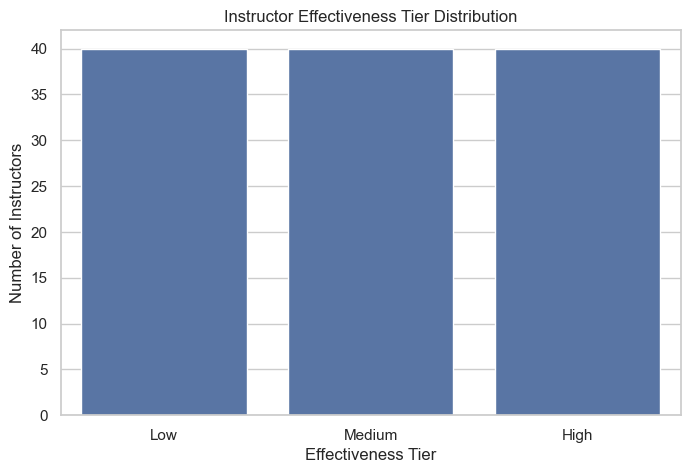

In [31]:

if "effectiveness_tier" not in instructor_df.columns:
    instructor_df["effectiveness_tier"] = pd.qcut(
        instructor_df["effectiveness_score"].rank(method="first"), 
        q=3, 
        labels=["Low", "Medium", "High"]
    )
    print("Effectiveness tiers successfully created!")


tier_counts = (
    instructor_df["effectiveness_tier"]
    .value_counts()
    .reindex(["Low", "Medium", "High"])
)


display(tier_counts.to_frame("Number of Instructors"))


plt.figure(figsize=(8, 5))

tier_df = tier_counts.reset_index()
tier_df.columns = ["effectiveness_tier", "count"]

sns.barplot(
    data=tier_df,
    x="effectiveness_tier",
    y="count"
)

plt.title("Instructor Effectiveness Tier Distribution")
plt.xlabel("Effectiveness Tier")
plt.ylabel("Number of Instructors")
plt.show()

In [32]:
comparison_columns = [
    "completion_rate",
    "dropout_rate",
    "avg_score_improvement",
    "avg_quiz_score",
    "avg_watch_time",
    "assignment_submission_rate",
    "forum_activity_rate",
    "avg_feedback_score",
    "num_batches",
    "num_courses"
]

tier_comparison = (
    instructor_df
    .groupby("effectiveness_tier", observed=False)[comparison_columns]
    .mean()
)

display(tier_comparison.round(3))

,completion_rate,dropout_rate,avg_score_improvement,avg_quiz_score,avg_watch_time,assignment_submission_rate,forum_activity_rate,avg_feedback_score,num_batches,num_courses
effectiveness_tier,,,,,,,,,,
Low,0.462,0.530,23.593,73.052,0.741,0.709,0.222,4.038,16.475,12.175
Medium,0.605,0.394,27.449,77.541,0.770,0.748,0.248,4.200,16.500,12.250
High,0.741,0.261,30.202,82.858,0.817,0.797,0.282,4.376,17.025,12.125


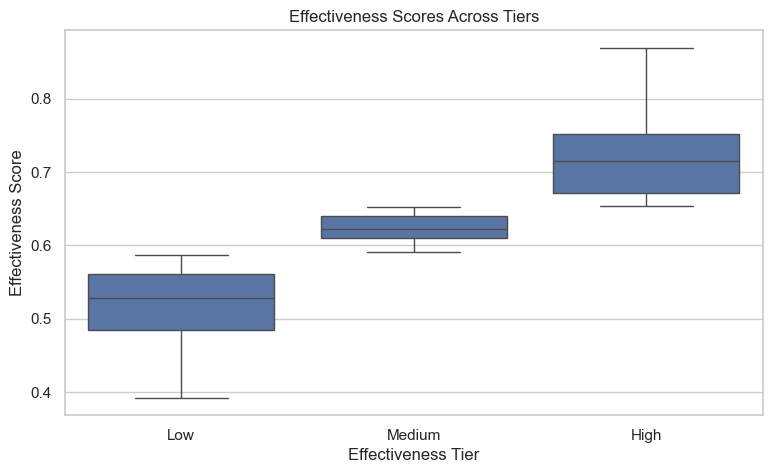

In [33]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=instructor_df,
    x="effectiveness_tier",
    y="effectiveness_score",
    order=["Low", "Medium", "High"]
)

plt.title("Effectiveness Scores Across Tiers")
plt.xlabel("Effectiveness Tier")
plt.ylabel("Effectiveness Score")
plt.show()

## Instructor-Level Aggregation

Each row in the original dataset represents a course batch. Since an instructor may teach multiple batches, batch-level metrics are aggregated by instructor using their mean values.

The number of unique courses and the number of batches are retained as additional features.

Mean aggregation provides a simple comparison across instructors, but it treats each batch equally because learner counts are not available in the dataset. Therefore, an instructor teaching one small batch may have a less stable average than an instructor teaching many batches.

The number of batches is retained to help interpret differences in data coverage. More batches indicate more observations, but do not automatically imply better teaching quality.

In [34]:
feature_columns = [
    "avg_watch_time",
    "assignment_submission_rate",
    "forum_activity_rate",
    "avg_feedback_score",
    "feedback_response_rate",
    "num_batches",
    "num_courses"
]

X = instructor_df[feature_columns].copy()

y = instructor_df["effectiveness_tier"].astype(str)

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nPredictor features:")
print(feature_columns)

print("\nTarget distribution:")
display(y.value_counts().to_frame("Count"))

Feature matrix shape: (120, 7)
Target shape: (120,)

Predictor features:
['avg_watch_time', 'assignment_submission_rate', 'forum_activity_rate', 'avg_feedback_score', 'feedback_response_rate', 'num_batches', 'num_courses']

Target distribution:


,Count
effectiveness_tier,
Medium,40
High,40
Low,40


,Proportion
effectiveness_tier,
Low,0.333333
Medium,0.333333
High,0.333333


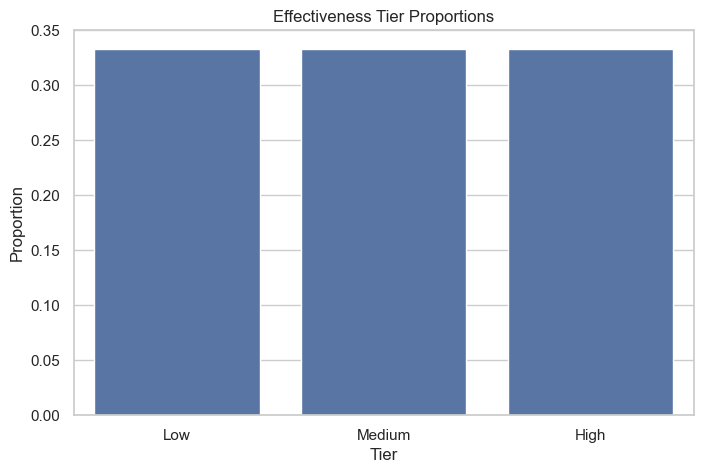

In [35]:
class_proportions = (
    y.value_counts(normalize=True)
    .reindex(["Low", "Medium", "High"])
)

display(class_proportions.to_frame("Proportion"))

plt.figure(figsize=(8, 5))

sns.barplot(
    x=class_proportions.index,
    y=class_proportions.values
)

plt.title("Effectiveness Tier Proportions")
plt.xlabel("Tier")
plt.ylabel("Proportion")
plt.show()

In [36]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

print("\nTraining target distribution:")
display(y_train.value_counts().to_frame("Count"))

print("\nTesting target distribution:")
display(y_test.value_counts().to_frame("Count"))

Training rows: 90
Testing rows: 30

Training target distribution:


,Count
effectiveness_tier,
Medium,30
High,30
Low,30



Testing target distribution:


,Count
effectiveness_tier,
Medium,10
Low,10
High,10


In [37]:
model = Pipeline(
    steps=[
        ("scaler", StandardScaler()),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=300,
                max_depth=5,
                min_samples_leaf=3,
                class_weight="balanced",
                random_state=RANDOM_STATE
            )
        )
    ]
)

model.fit(X_train, y_train)

print("Random Forest model trained successfully.")

Random Forest model trained successfully.


In [38]:
y_pred = model.predict(X_test)

results_df = pd.DataFrame({
    "Actual_Tier": y_test.to_numpy(),
    "Predicted_Tier": y_pred
})

display(results_df.head(15))

,Actual_Tier,Predicted_Tier
0,Medium,High
1,Low,Medium
2,Low,Low
3,High,Medium
4,High,High
5,Low,Low
6,High,Medium
7,Medium,Medium
8,High,High
9,Low,Low


In [39]:
accuracy = accuracy_score(y_test, y_pred)

balanced_acc = balanced_accuracy_score(y_test, y_pred)

macro_f1 = f1_score(
    y_test,
    y_pred,
    average="macro"
)

print(f"Accuracy: {accuracy:.3f}")
print(f"Balanced Accuracy: {balanced_acc:.3f}")
print(f"Macro F1 Score: {macro_f1:.3f}")

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        y_pred,
        labels=["Low", "Medium", "High"],
        zero_division=0
    )
)

Accuracy: 0.633
Balanced Accuracy: 0.633
Macro F1 Score: 0.638

Classification Report:
              precision    recall  f1-score   support

         Low       0.70      0.70      0.70        10
      Medium       0.45      0.50      0.48        10
        High       0.78      0.70      0.74        10

    accuracy                           0.63        30
   macro avg       0.64      0.63      0.64        30
weighted avg       0.64      0.63      0.64        30



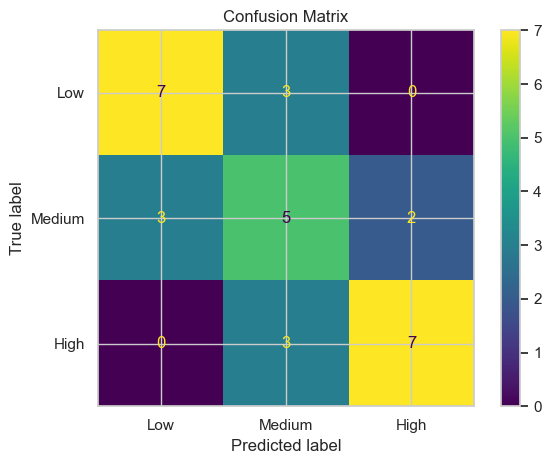

In [40]:
class_order = ["Low", "Medium", "High"]

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=class_order
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_order
)

disp.plot(values_format="d")

plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

In [41]:
baseline = DummyClassifier(strategy="most_frequent")

baseline.fit(X_train, y_train)

baseline_pred = baseline.predict(X_test)

baseline_accuracy = accuracy_score(
    y_test,
    baseline_pred
)

baseline_balanced_accuracy = balanced_accuracy_score(
    y_test,
    baseline_pred
)

print(f"Baseline Accuracy: {baseline_accuracy:.3f}")
print(f"Random Forest Accuracy: {accuracy:.3f}")

print(
    f"Baseline Balanced Accuracy: {baseline_balanced_accuracy:.3f}"
)

print(
    f"Random Forest Balanced Accuracy: {balanced_acc:.3f}"
)

Baseline Accuracy: 0.333
Random Forest Accuracy: 0.633
Baseline Balanced Accuracy: 0.333
Random Forest Balanced Accuracy: 0.633


In [42]:
cv_model = Pipeline(
    steps=[
        ("scaler", StandardScaler()),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=300,
                max_depth=5,
                min_samples_leaf=3,
                class_weight="balanced",
                random_state=RANDOM_STATE
            )
        )
    ]
)

cv_scores = cross_val_score(
    cv_model,
    X,
    y,
    cv=5,
    scoring="balanced_accuracy"
)

print("Cross-validation balanced accuracy scores:")
print(np.round(cv_scores, 3))

print("Mean CV balanced accuracy:", round(cv_scores.mean(), 3))
print("Standard deviation:", round(cv_scores.std(), 3))

Cross-validation balanced accuracy scores:
[0.75  0.583 0.792 0.708 0.792]
Mean CV balanced accuracy: 0.725
Standard deviation: 0.077


,Feature,Importance
4,feedback_response_rate,0.310919
3,avg_feedback_score,0.222509
1,assignment_submission_rate,0.143929
2,forum_activity_rate,0.138282
0,avg_watch_time,0.122553
6,num_courses,0.030939
5,num_batches,0.030869


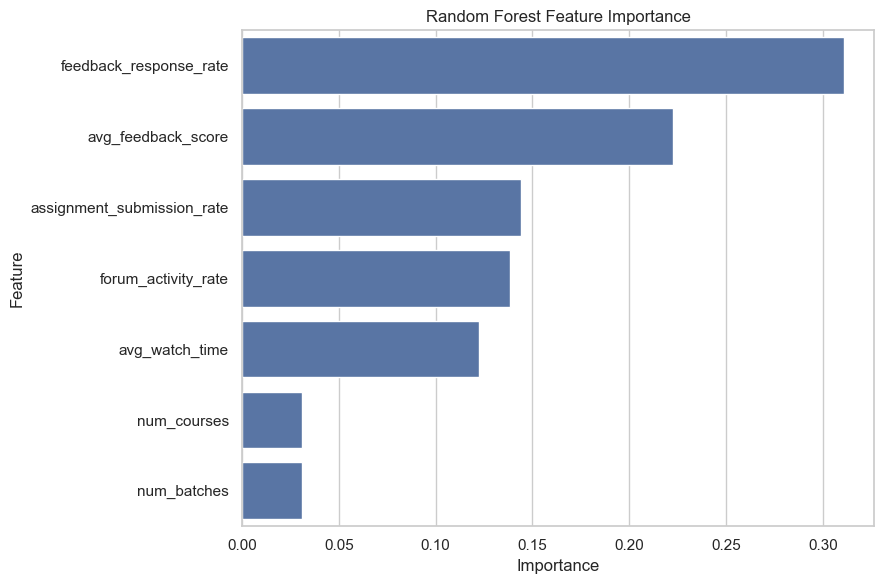

In [43]:
rf = model.named_steps["classifier"]

importance_df = pd.DataFrame({
    "Feature": feature_columns,
    "Importance": rf.feature_importances_
}).sort_values(
    by="Importance",
    ascending=False
)

display(importance_df)

plt.figure(figsize=(9, 6))

sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature"
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [44]:
print("===== MODEL EVALUATION SUMMARY =====")

print(f"Accuracy: {accuracy:.3f}")
print(f"Balanced accuracy: {balanced_acc:.3f}")
print(f"Macro F1: {macro_f1:.3f}")

print(f"Baseline accuracy: {baseline_accuracy:.3f}")
print(f"Baseline balanced accuracy: {baseline_balanced_accuracy:.3f}")

print(f"Mean CV balanced accuracy: {cv_scores.mean():.3f}")
print(f"CV standard deviation: {cv_scores.std():.3f}")

if balanced_acc > baseline_balanced_accuracy:
    print("\nThe model outperformed the baseline on balanced accuracy.")
else:
    print("\nThe model did not outperform the baseline on balanced accuracy.")

print("\nInterpret the class-wise precision and recall before drawing conclusions.")

===== MODEL EVALUATION SUMMARY =====
Accuracy: 0.633
Balanced accuracy: 0.633
Macro F1: 0.638
Baseline accuracy: 0.333
Baseline balanced accuracy: 0.333
Mean CV balanced accuracy: 0.725
CV standard deviation: 0.077

The model outperformed the baseline on balanced accuracy.

Interpret the class-wise precision and recall before drawing conclusions.


## 1. Which Features Most Influenced Instructor Effectiveness, and Why?

The effectiveness score was constructed using completion rate, score improvement, quiz score, dropout rate, engagement, and feedback.

The Random Forest model uses engagement, feedback, and teaching-exposure indicators to predict effectiveness tiers. The feature importance output identifies which predictors the trained model relies on most.

The actual ranking should be discussed using the feature importance table generated by the notebook. Feature importance indicates predictive usefulness within this model and does not establish a causal relationship with instructor effectiveness.

## 2. Which Variables Could Be Misleading or Confounded?

Several variables may be influenced by factors other than instructor performance.

- Completion rate can be affected by learner availability and course difficulty.
- Dropout rate may reflect personal circumstances or scheduling issues.
- Quiz scores depend on prior knowledge and assessment difficulty.
- Watch time does not necessarily indicate understanding.
- Assignment submission rates can depend on workload and assignment complexity.
- Feedback scores may be affected by expectations and response bias.
- Batch count measures teaching exposure, not teaching quality.

These factors mean that observed relationships should be interpreted cautiously. Correlation does not establish causation.

## 3. How Could This Model Fail in Real-World Usage?

The model may perform poorly on instructors, courses, or learner populations that differ from those represented in the training data.

The target tiers are based on a constructed score rather than independently verified teaching-quality labels. The model may therefore learn associations with engagement and feedback without accurately measuring teaching effectiveness.

Results may also be unreliable for instructors with very few batches. Changes in course difficulty, assessment practices, and learner behavior could reduce predictive performance.

Before deployment, the model should be tested on future data and previously unseen instructors.

## 4. What Additional Data Would Improve This Analysis?

Useful additional data would include:

- Number of learners enrolled in each batch.
- Learner pre-course knowledge and baseline assessment scores.
- Course difficulty, duration, and assessment standards.
- Instructor experience and subject expertise.
- Attendance and independently measured learning gains.
- Qualitative feedback and teaching observations.
- Historical records across different courses and time periods.

Learner counts would make it possible to calculate weighted averages instead of treating every batch equally. Independent measures of learning gains would also help validate the effectiveness score.

## 5. Should This Model Be Used for Instructor Performance Evaluation?

The model should not be used as the sole basis for instructor evaluation, compensation, promotion, or termination.

The effectiveness score uses assumed weights and indirect performance indicators. It has not been independently validated as a measure of teaching quality, and the model may reflect learner circumstances or course differences rather than instructor performance.

It could be used as an exploratory decision-support tool to identify batches that may need further investigation or support. Any consequential decision should involve additional evidence, fairness checks, human review, and an opportunity for instructors to provide context.

## Practical Applications in an EdTech Platform

The analysis could help an EdTech platform identify patterns in course completion, engagement, and learner feedback.

1. **Learner support:** Investigate batches with low completion or assignment submission rates.
2. **Instructor development:** Offer additional training or mentoring where multiple indicators suggest that support may be useful.
3. **Course improvement:** Review course difficulty, assessment design, and content when learner outcomes are consistently weak.
4. **Feedback monitoring:** Track feedback patterns while considering the number of learners who responded.
5. **Ongoing validation:** Monitor model performance on future batches and investigate whether predictions differ across courses.

The model should support investigation and improvement rather than automatically label instructors as good or bad.

In [45]:
print("=" * 50)
print("INSTRUCTOR EFFECTIVENESS PROJECT SUMMARY")
print("=" * 50)

print("\nDataset")
print("Total batches:", len(df))
print("Unique instructors:", df["instructor_id"].nunique())
print("Unique courses:", df["course_id"].nunique())

print("\nEffectiveness tiers")
display(
    instructor_df["effectiveness_tier"]
    .value_counts()
    .reindex(["Low", "Medium", "High"])
    .to_frame("Number of Instructors")
)

print("\nModel evaluation")
print("Accuracy:", round(accuracy, 3))
print("Balanced accuracy:", round(balanced_acc, 3))
print("Macro F1:", round(macro_f1, 3))

print("\nTop predictive features")
display(importance_df.head(5))

print("\nCross-validation")
print("Mean balanced accuracy:", round(cv_scores.mean(), 3))
print("Standard deviation:", round(cv_scores.std(), 3))

INSTRUCTOR EFFECTIVENESS PROJECT SUMMARY

Dataset
Total batches: 2000
Unique instructors: 120
Unique courses: 25

Effectiveness tiers


,Number of Instructors
effectiveness_tier,
Low,40
Medium,40
High,40



Model evaluation
Accuracy: 0.633
Balanced accuracy: 0.633
Macro F1: 0.638

Top predictive features


,Feature,Importance
4,feedback_response_rate,0.310919
3,avg_feedback_score,0.222509
1,assignment_submission_rate,0.143929
2,forum_activity_rate,0.138282
0,avg_watch_time,0.122553



Cross-validation
Mean balanced accuracy: 0.725
Standard deviation: 0.077


In [46]:
instructor_df.to_csv(
    "instructor_effectiveness_analysis.csv",
    index=False
)

print("Instructor-level results saved.")

Instructor-level results saved.


In [47]:
results_df.to_csv(
    "instructor_effectiveness_predictions.csv",
    index=False
)

print("Model predictions saved.")

Model predictions saved.


## Conclusion

This project analyzes instructor effectiveness using batch-level learner outcomes, engagement metrics, and feedback data.

The analysis includes data validation, exploratory visualizations, a weighted effectiveness score, instructor-level aggregation, and a Random Forest classifier for Low, Medium, and High effectiveness tiers.

Model performance is assessed using accuracy, balanced accuracy, precision, recall, macro F1 score, a confusion matrix, baseline comparison, and cross-validation.

The results should be interpreted as exploratory findings. The effectiveness tiers depend on the assumptions used to construct the score, and model predictions do not independently establish teaching quality. Further validation with independent learning outcomes and data from unseen instructors is required before practical use.